# 01 RNA-seq のデータを見てみる

RNA-seq の解析で、Mappingの後に生成される**カウント表**を開いてみます。

## この実習で使うデータ

ヒトの乳がん由来の培養細胞 MCF7 を使った実験のデータです。Sato らの論文（PNAS, 2024）で使われ、DDBJ に DRA011729 として公開されています。STARを使ってMappingし、RSEMでカウントしました。

- **shPPP3CA**：*PPP3CA* 遺伝子を shRNA でノックダウンした細胞。*PPP3CA* は、脱リン酸化酵素カルシニューリンの本体（触媒サブユニット）の遺伝子です
- **shControl**：対照の shRNA を入れた細胞。Controlとして利用しています。

論文は、カルシニューリンが転写因子 E2F1 のタンパク質を安定にする、と報告しています。この実習では、*PPP3CA* を減らした細胞で、どの遺伝子の RNA 量が、そしてどの遺伝子セットが変化するかを調べます。


## Google Colab の使い方

- 灰色の枠（セル）を選び、Shift + Enter で実行します。(もしくは, 左の ▶ を押す)
- 上から順に実行してください。途中から始めると、前のセルで作った変数がなくてエラーになります
- 最初のセルを実行したときに「警告: このノートブックは Google が作成したものではありません」と出たら、「このまま実行」を押します
- このページを閉じると、Colab の中で作ったファイルは消えます。

## 準備

下のセルを実行して、配布元から `counts.csv`, `samples.csv` をダウンロードします。

In [1]:
import warnings
warnings.filterwarnings("ignore")  # 計算には影響しない警告を表示しない

DATA_URL = "https://pub-fcc6b90fb32448a4b3b455e664df76f0.r2.dev/e2f1-rnaseq/v1/"
!wget -q -nc {DATA_URL}counts.csv
!wget -q -nc {DATA_URL}samples.csv
!ls -l counts.csv samples.csv

-rw-r--r-- 1 root root 546052 Oct 25 05:53 counts.csv
-rw-r--r-- 1 root root    213 Oct 25 05:54 samples.csv


## 試料の情報を読む

`samples.csv` には、試料の名前と条件の対応が書いてあります。`accession` は、DDBJ に登録されたデータの番号です。

In [ ]:
import pandas as pd

samples = pd.read_csv("samples.csv", index_col="sample")
samples

,condition,accession
sample,,
shControl_1,shControl,DRR279207
shControl_2,shControl,DRR279208
shControl_3,shControl,DRR279209
shPPP3CA_1,shPPP3CA,DRR279210
shPPP3CA_2,shPPP3CA,DRR279211
shPPP3CA_3,shPPP3CA,DRR279212


## カウント表を読む

カウント表は、1行が1つの遺伝子、1列が1つの試料です。1つのマスには、その遺伝子に割り当てられたリードの数が入っています。

In [ ]:
counts = pd.read_csv("counts.csv", index_col="gene")
print("遺伝子の数:", counts.shape[0])
print("試料の数:", counts.shape[1])
counts.head()

遺伝子の数: 20331
試料の数: 6


,shControl_1,shControl_2,shControl_3,shPPP3CA_1,shPPP3CA_2,shPPP3CA_3
gene,,,,,,
A1BG,33,36,36,36,47,40
A1CF,0,2,0,0,2,0
A2M,0,0,0,2,0,1
A2ML1,20,12,24,14,17,20
A3GALT2,0,1,1,0,0,0


## 試料ごとのカウントの合計

試料ごとに、全遺伝子のカウントを足してみます。

In [ ]:
total = counts.sum()
total

,0
shControl_1,18820462
shControl_2,17222310
shControl_3,15380328
shPPP3CA_1,17847060
shPPP3CA_2,15972406
shPPP3CA_3,17524561


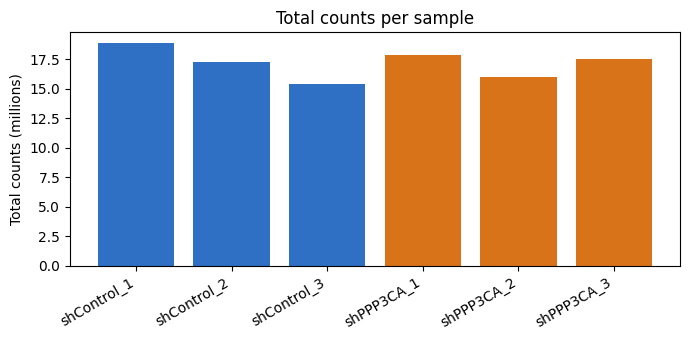

In [ ]:
import matplotlib.pyplot as plt

colors = ["#2F6FC4" if c == "shControl" else "#D9731A" for c in samples.loc[total.index, "condition"]]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(total.index, total / 1e6, color=colors)
ax.set_ylabel("Total counts (millions)")
ax.set_title("Total counts per sample")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

合計は試料ごとに少しずつ違います。合計が多い試料では、どの遺伝子のカウントも多めに出やすくなります。そのため、カウントをそのまま比べず、03 で合計などの違いを調整（正規化）してから比べます。

## 次へ

次は **02_QC_PCA** に進みます。
[https://colab.research.google.com/github/Yokohide0317/what_is_BI/blob/main/public/colab/02_QC_PCA.ipynb](https://colab.research.google.com/github/Yokohide0317/what_is_BI/blob/main/public/colab/02_QC_PCA.ipynb)